# 02 - Análise exploratória dos dados brutos

**Objetivo:** Compreender distribuições, relações e eventos antes de qualquer tratamento.

> Execute as células na ordem. As saídas são gravadas nas pastas do projeto.

In [26]:
from pathlib import Path
import sys, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Localiza a raiz do projeto independentemente de o notebook ser aberto pela pasta raiz ou notebooks.
CANDIDATOS=[Path.cwd(), Path.cwd().parent]
ROOT=next((p.resolve() for p in CANDIDATOS if (p/'dados').exists() and (p/'notebooks').exists()),None)
if ROOT is None: raise FileNotFoundError('Abra o VS Code na pasta projeto_soft_sensor.')
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from src.funcoes import *
sns.set_theme(style='whitegrid')
print('Raiz:',ROOT)


Raiz: D:\UNICAMP\Mestrado\AP539_Aprendizado_estatistico\Trabalho\Projeto\projeto_soft_sensor


## Carregamento

In [27]:
dados=carregar_csv(ROOT/'dados/02_intermediarios/dados_sincronizados.csv')
print('Shape:',dados.shape)
if 'status_sincronizacao' in dados.columns:
    print('Status sincronizacao:\n',dados['status_sincronizacao'].value_counts().to_string())
display(dados.head())


Shape: (29546, 19)
Status sincronizacao:
 status_sincronizacao
sensor+clima    29546


,tempo,temperatura_interna_C,umidade_relativa_interna_pct,ponto_orvalho_131,radiacao_inst_133,radiacao_acum_134,rssi_d_169,rssi_u_170,umidade_relativa2_439,ponto_orvalho2_440,dpv2_441,co2_444,temperatura_ambiente_C,umidade_relativa_ar_pct,radiacao_solar_global_W_m2,temperatura_ponto_orvalho_C,velocidade_vento_m_s,timestamp,status_sincronizacao
0,2026-10-01 19:04:55-03:00,20.2,96.0,19.54,0.0,473.52,-91.0,-89.5,96.0,19.24,0.09,-36.0,20.0,95.0,0.0,19.2,1.98,2026-10-01 19:04:55-03:00,sensor+clima
1,2026-10-01 19:09:56-03:00,20.4,95.9,19.72,0.0,473.52,-91.0,-89.5,95.7,19.39,0.10,-36.0,20.0,95.0,0.0,19.2,1.60,2026-10-01 19:09:56-03:00,sensor+clima
2,2026-10-01 19:14:58-03:00,20.4,95.4,19.64,0.0,473.52,-90.5,-93.0,95.0,19.27,0.12,-36.0,20.0,95.0,0.0,19.2,1.60,2026-10-01 19:14:58-03:00,sensor+clima
3,2026-10-01 19:15:58-03:00,20.4,95.3,19.62,0.0,473.52,-90.5,-90.0,95.0,19.37,0.12,-36.0,20.0,95.0,0.0,19.2,1.60,2026-10-01 19:15:58-03:00,sensor+clima
4,2026-10-01 19:16:58-03:00,20.4,95.2,19.61,0.0,473.52,-91.0,-89.5,94.9,19.26,0.12,-36.0,20.0,95.0,0.0,19.2,1.60,2026-10-01 19:16:58-03:00,sensor+clima


## Estatísticas e ausências

,count,mean,std,min,25%,50%,75%,max,mediana,assimetria,curtose,ausentes_pct
temperatura_interna_C,29546.0,23.835487,5.815665,14.70,19.30,21.90,28.3000,42.10,21.90,0.722580,-0.483294,0.0
umidade_relativa_interna_pct,29546.0,75.435693,19.300738,25.50,58.10,81.50,92.3000,99.70,81.50,-0.630962,-0.897040,0.0
ponto_orvalho_131,29546.0,18.498756,2.331132,11.06,17.23,18.86,20.0700,24.77,18.86,-0.519072,-0.042562,0.0
radiacao_inst_133,29546.0,162.008693,235.842443,0.00,0.00,0.00,271.9225,977.74,0.00,1.302283,0.352510,0.0
radiacao_acum_134,29546.0,2228.395906,2654.779494,0.02,531.01,1063.83,2830.5075,10343.04,1063.83,1.509973,1.042951,0.0
rssi_d_169,29546.0,-90.437521,3.962943,-109.50,-93.00,-90.50,-88.0000,-80.50,-90.50,-0.190903,0.253156,0.0
rssi_u_170,29546.0,-89.227442,4.164044,-110.50,-91.50,-89.50,-86.5000,-78.50,-89.50,-0.013667,0.112960,0.0
umidade_relativa2_439,29546.0,76.945800,18.258486,26.90,61.30,82.40,93.1000,98.90,82.40,-0.688317,-0.735386,0.0
ponto_orvalho2_440,29546.0,18.229199,2.341418,11.12,16.94,18.56,19.8000,24.35,18.56,-0.452067,-0.147502,0.0
dpv2_441,29546.0,0.861547,0.941530,0.02,0.15,0.43,1.4100,4.80,0.43,1.361703,1.188771,0.0


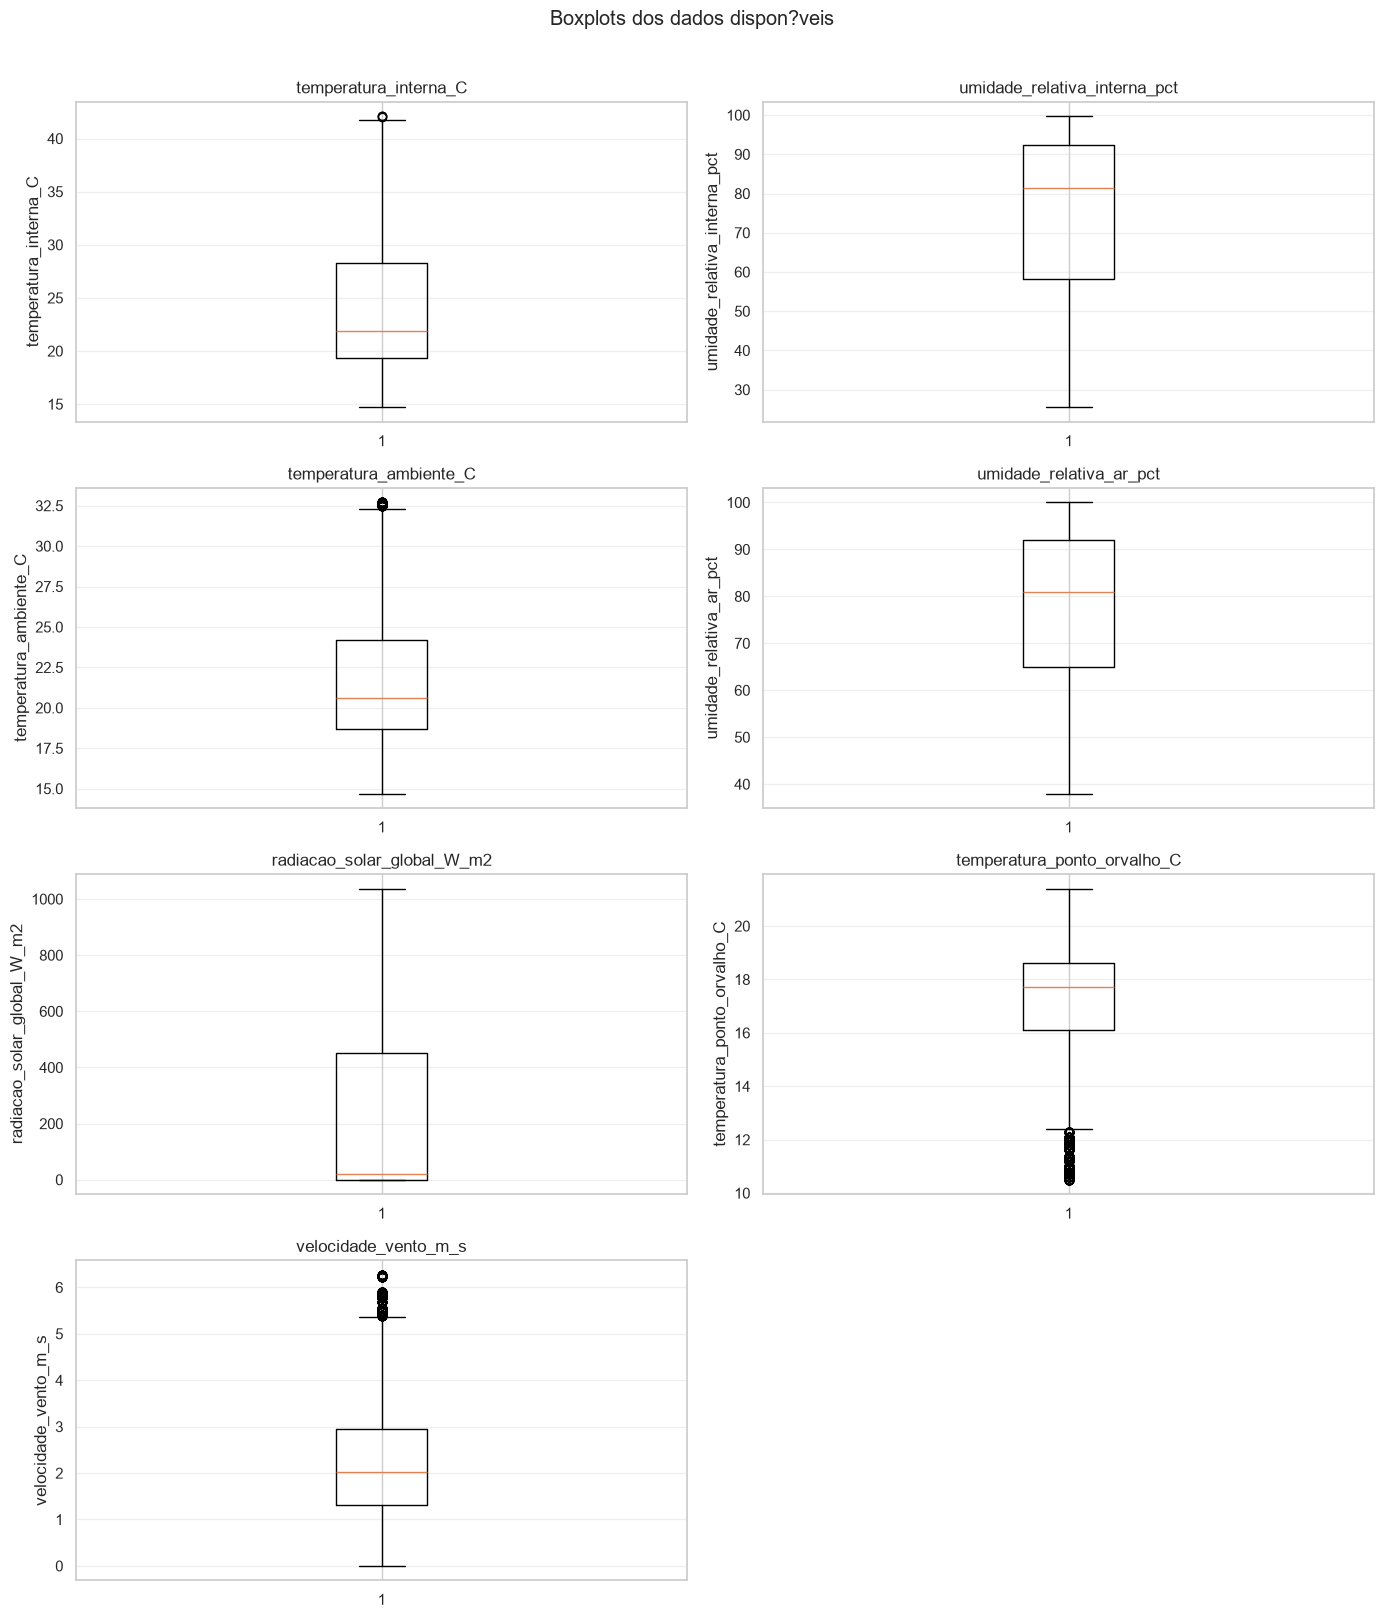

In [28]:
nums=dados.select_dtypes(include='number')
estat=nums.describe().T
estat['mediana']=nums.median()
estat['assimetria']=nums.skew()
estat['curtose']=nums.kurtosis()
estat['ausentes_pct']=nums.isna().mean()*100
display(estat)
estat.to_csv(ROOT/'resultados/tabelas/estatisticas_descritivas_brutos.csv',encoding='utf-8-sig')
variaveis_boxplot=[c for c in ['temperatura_interna_C','umidade_relativa_interna_pct','temperatura_ambiente_C','umidade_relativa_ar_pct','radiacao_solar_global_W_m2','temperatura_ponto_orvalho_C','velocidade_vento_m_s'] if c in dados.columns and dados[c].notna().any()]
if not variaveis_boxplot:
    variaveis_boxplot=[c for c in nums.columns if dados[c].notna().any()][:4]
if variaveis_boxplot:
    nrows=(len(variaveis_boxplot)+1)//2
    fig, axs = plt.subplots(nrows, 2, figsize=(14, 4*nrows))
    if nrows == 1:
        axs = np.atleast_1d(axs)
    for ax, coluna in zip(axs.flat, variaveis_boxplot):
        ax.boxplot(dados[coluna].dropna())
        ax.set_title(coluna)
        ax.set_ylabel(coluna)
        ax.grid(axis='y', alpha=0.3)
    for ax in axs.flat[len(variaveis_boxplot):]:
        ax.set_visible(False)
    fig.suptitle('Boxplots dos dados dispon?veis', y=1.01)
    fig.tight_layout()
    fig.savefig(ROOT/'resultados/figuras/dados_brutos/boxplots_variaveis_principais.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print('Nenhuma vari?vel com dados validos para boxplot nesta fonte.')


## Séries temporais principais

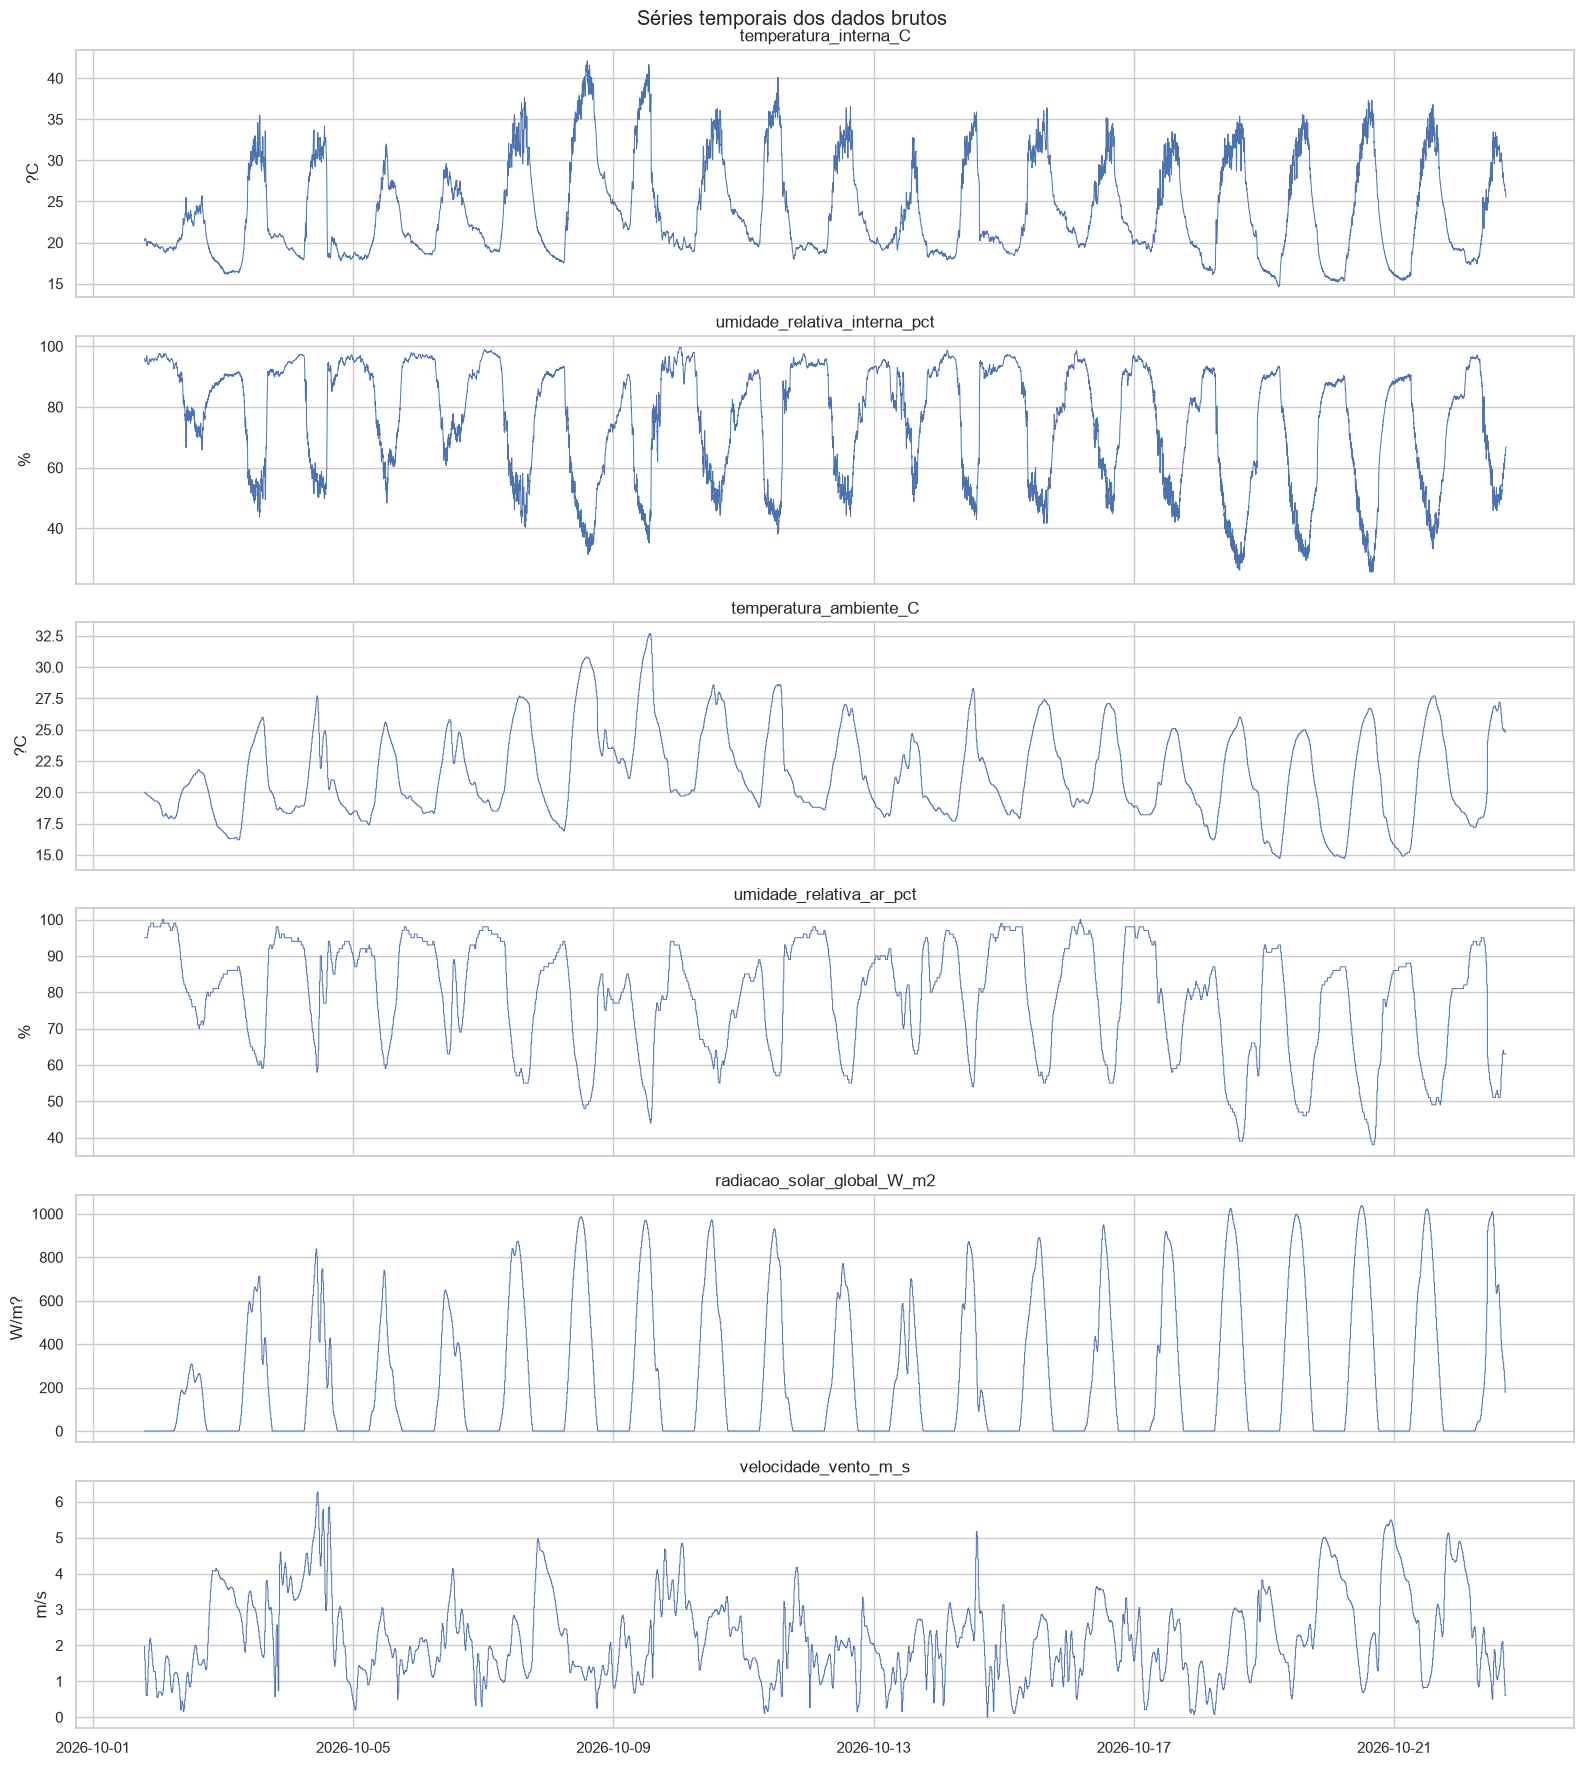

In [29]:
series = [('temperatura_interna_C','?C'), ('umidade_relativa_interna_pct','%')]
if 'temperatura_ambiente_C' in dados.columns and dados['temperatura_ambiente_C'].notna().any():
    series.append(('temperatura_ambiente_C','?C'))
if 'umidade_relativa_ar_pct' in dados.columns and dados['umidade_relativa_ar_pct'].notna().any():
    series.append(('umidade_relativa_ar_pct','%'))
if 'radiacao_solar_global_W_m2' in dados.columns and dados['radiacao_solar_global_W_m2'].notna().any():
    series.append(('radiacao_solar_global_W_m2','W/m?'))
if 'velocidade_vento_m_s' in dados.columns and dados['velocidade_vento_m_s'].notna().any():
    series.append(('velocidade_vento_m_s','m/s'))
fig, axs = plt.subplots(len(series), 1, figsize=(16, 3*len(series)), sharex=True)
if len(series) == 1:
    axs = [axs]
for ax, (col, unidade) in zip(axs, series):
    ax.plot(dados.timestamp, dados[col], lw=.7)
    ax.set_ylabel(unidade)
    ax.set_title(col)
fig.suptitle('Séries temporais dos dados brutos')
fig.tight_layout()
fig.savefig(ROOT/'resultados/figuras/dados_brutos/02_series_30_dias.png',dpi=150)
plt.show()


## Distribuições e correlações

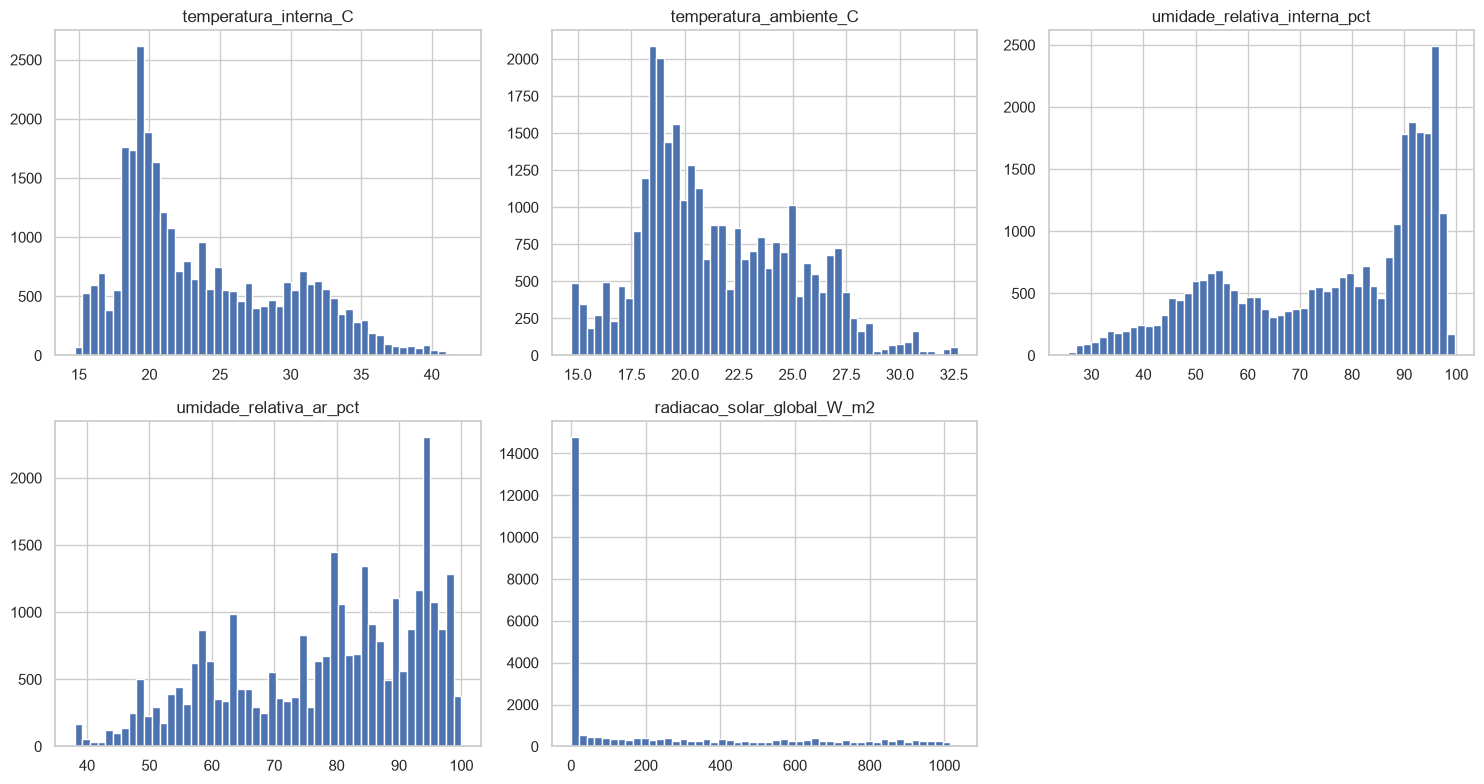

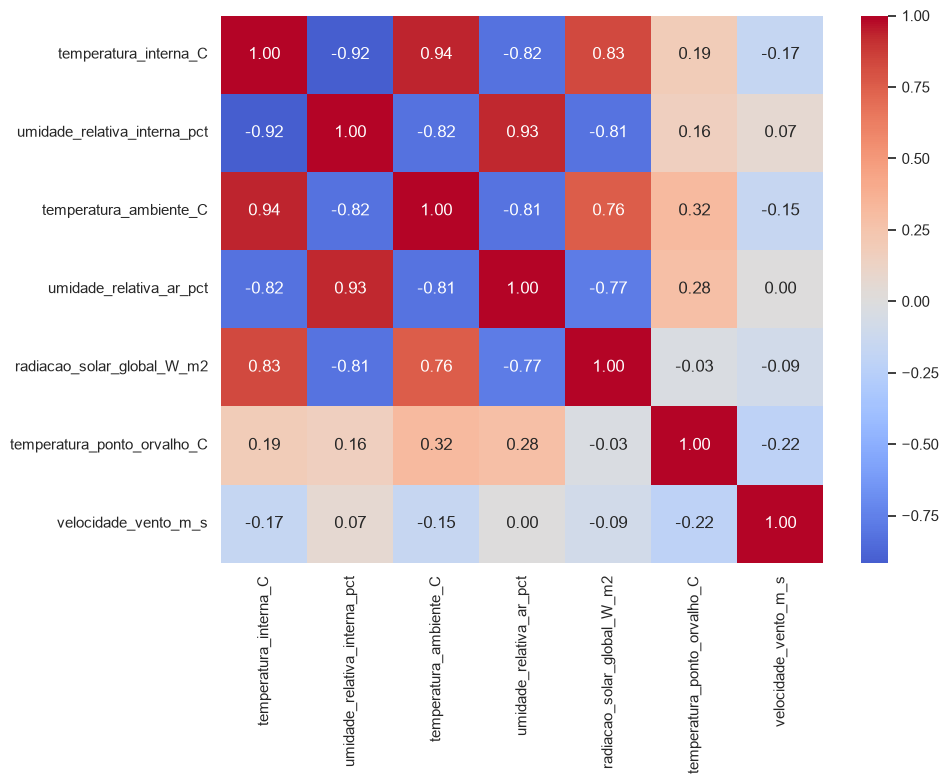

In [30]:
cols=[c for c in ['temperatura_interna_C','temperatura_ambiente_C','umidade_relativa_interna_pct','umidade_relativa_ar_pct','radiacao_solar_global_W_m2'] if c in dados.columns and dados[c].notna().any()]
if not cols:
    cols=[c for c in dados.select_dtypes(include='number').columns if dados[c].notna().any()][:5]
if cols:
    fig, axs = plt.subplots(max(1, (len(cols)+2)//3), 3, figsize=(15, 4*max(1, (len(cols)+2)//3)))
    for ax, c in zip(axs.ravel(), cols):
        ax.hist(dados[c].dropna(), bins=50)
        ax.set_title(c)
    for ax in axs.ravel()[len(cols):]:
        ax.axis('off')
    fig.tight_layout()
    fig.savefig(ROOT/'resultados/figuras/dados_brutos/03_distribuicoes.png',dpi=150)
    plt.show()
corr_cols=[c for c in ['temperatura_interna_C','umidade_relativa_interna_pct','temperatura_ambiente_C','umidade_relativa_ar_pct','radiacao_solar_global_W_m2','temperatura_ponto_orvalho_C','velocidade_vento_m_s'] if c in dados.columns and dados[c].notna().any()]
if len(corr_cols) > 1:
    corr=dados[corr_cols].corr()
    plt.figure(figsize=(10,8))
    sns.heatmap(corr,annot=True,fmt='.2f',cmap='coolwarm',center=0)
    plt.tight_layout()
    plt.savefig(ROOT/'resultados/figuras/dados_brutos/04_correlacoes.png',dpi=150)
    plt.show()
else:
    print('N?o h? quantidade suficiente de colunas num?ricas para calcular correla??es na fonte atual.')


## Eventos conhecidos

Fonte real sem coluna evento_referencia: n?o h? eventos sint?ticos para inspecionar.


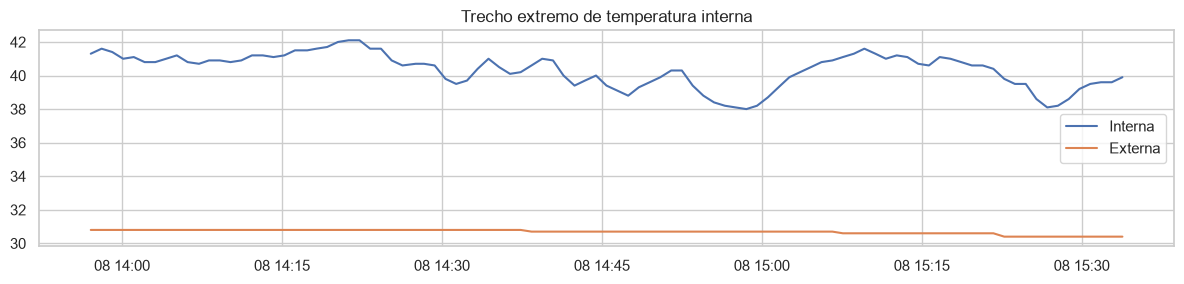

In [31]:
if 'evento_referencia' in dados.columns:
    display(dados.evento_referencia.value_counts().to_frame('registros'))
    for evento in ['onda_de_calor_real','sensor_travado_temperatura','ruido_excessivo_temperatura','falha_de_comunicacao','pico_isolado_desconhecido','valor_fisicamente_impossivel']:
        m=dados.evento_referencia.eq(evento)
        if not m.any(): continue
        i=np.where(m)[0][0]; rec=dados.iloc[max(0,i-24):min(len(dados),i+72)]
        fig,ax=plt.subplots(figsize=(12,3)); ax.plot(rec.timestamp,rec.temperatura_interna_C,label='Interna');
        if 'temperatura_ambiente_C' in rec.columns and rec['temperatura_ambiente_C'].notna().any():
            ax.plot(rec.timestamp,rec.temperatura_ambiente_C,label='Externa')
        ax.set_title(evento); ax.legend(); fig.tight_layout(); fig.savefig(ROOT/f'resultados/figuras/dados_brutos/evento_{evento}.png',dpi=140); plt.show()
else:
    print('Fonte real sem coluna evento_referencia: n?o h? eventos sint?ticos para inspecionar.')
    temp = dados['temperatura_interna_C'].dropna()
    if temp.empty:
        print('Nenhuma s?rie de temperatura interna dispon?vel para an?lise do trecho extremo.')
    else:
        idx = temp.index[temp.argmax()]
        rec = dados.iloc[max(0, idx-24):min(len(dados), idx+72)]
        fig,ax=plt.subplots(figsize=(12,3)); ax.plot(rec.timestamp, rec.temperatura_interna_C, label='Interna');
        if 'temperatura_ambiente_C' in rec.columns and rec['temperatura_ambiente_C'].notna().any():
            ax.plot(rec.timestamp, rec.temperatura_ambiente_C, label='Externa')
        ax.set_title('Trecho extremo de temperatura interna'); ax.legend(); fig.tight_layout(); fig.savefig(ROOT/'resultados/figuras/dados_brutos/evento_trecho_extremo_temperatura.png',dpi=140); plt.show()


## Conclusões da etapa

Execute todas as células, registre as observações exibidas e confirme os arquivos gerados antes de avançar para o notebook seguinte.